# Collect Fixed Platform Coverage (Towers and Tethered Balloons)

This example demonstrates how to use direct function calls of the low-level TAT-C library to collect the coverage footprints of instruments on fixed surface platforms, such as towers and tethered balloons, using the `SurfacePlatform` schema and the `collect_platform_track`/`compute_platform_track` analysis functions.

A fixed platform combines features of two other TAT-C observing systems. Like a ground-based radar (see the [Collect Radar Coverage](CollectRadarTrack.ipynb) example), it does not move in the Earth-fixed frame, so these functions report one static footprint per platform and instrument rather than a time series. Like a satellite (see the [Collect Orbit and Ground Track](CollectOrbitGroundTrack.ipynb) example), it hosts generic (`Instrument`) or pointed (`PointedInstrument`) instruments, whose views are projected onto a target elevation exactly as a satellite's ground track is.

The platforms in this example are hypothetical, sited around Phoenix, Arizona.

## Tethered Balloon

A `SurfacePlatform` is located by its `latitude`, `longitude`, and ground `elevation`, with its instruments a `height` above the ground (for example, a tower's height or a tethered balloon's altitude above its tether point). Elevations are heights above the WGS 84 ellipsoid, the surface onto which footprints are projected. Around Phoenix, these are about 30 m less than heights above mean sea level (the geoid undulation).

The first platform is a tethered balloon flying 1,000 m above downtown Phoenix, where the ground is about 330 m above mean sea level (300 m above the ellipsoid). It carries two generic instruments, each observing a cone around nadir:

 * `Camera`: a 60 degree field of regard, as for a downward-looking camera.
 * `Horizon`: a 180 degree field of regard, which observes everything below the horizon.

In [1]:
from tatc.schemas import Instrument, SurfacePlatform

balloon = SurfacePlatform(
    name="Balloon",
    latitude=33.4484,
    longitude=-112.0740,
    elevation=300,
    height=1000,
    instruments=[
        Instrument(name="Camera", field_of_regard=60),
        Instrument(name="Horizon", field_of_regard=180),
    ],
)

The `collect_platform_track` method computes each instrument's footprint. By default it projects onto the platform's ground elevation; pass `elevation` to use another target elevation, which must be below the instruments. As in `collect_ground_track`, `instrument_index` selects one instrument of each platform (the first by default), or `None` selects all of them. Results are formatted as a flat GeoDataFrame, similar to a regular pandas DataFrame with a geospatial column labeled `geometry`. Other columns:
 * `platform`: platform name
 * `instrument`: instrument name
 * `elevation`: target elevation (m) onto which the footprint is projected

In [2]:
from tatc.analysis import collect_platform_track

results = collect_platform_track(balloon, instrument_index=None)
display(results)

,platform,instrument,elevation,geometry
0,Balloon,Camera,300.0,"POLYGON Z ((-112.08021 33.4484 300, -112.08008..."
1,Balloon,Horizon,300.0,"POLYGON Z ((-113.2892 33.44245 300, -113.26703..."


To measure footprints, it helps to transform them into a local azimuthal equidistant projection centered on the platform, in which coordinates are distances (m) east and north of it. From 1,000 m, the camera's footprint is a disk of radius 1,000 tan(30°) = 577 m. The horizon instrument sees out to the horizon, about √(2Rh) ≈ 113 km away for a height h and Earth radius R. Rays that miss the target surface (looking above the horizon) are projected onto the horizon, as for a satellite's view of the Earth's limb.

In [3]:
import numpy as np


def local_crs(platform):
    """Azimuthal equidistant projection (m) centered on a platform."""
    return f"+proj=aeqd +lat_0={platform.latitude} +lon_0={platform.longitude} +datum=WGS84 +units=m"


def mean_radius(track, platform):
    """Mean distance (m) from a platform to the boundary of each footprint."""
    local = track.to_crs(local_crs(platform))
    return local.geometry.apply(lambda g: np.hypot(*np.array(g.exterior.coords)[:, :2].T).mean())


summary = results[["platform", "instrument", "elevation"]].copy()
summary["radius (km)"] = mean_radius(results, balloon) / 1e3
summary["area (km2)"] = results.to_crs(local_crs(balloon)).area / 1e6
display(summary.round(3))

,platform,instrument,elevation,radius (km),area (km2)
0,Balloon,Camera,300.0,0.577,1.040
1,Balloon,Horizon,300.0,112.863,39741.534


The footprints can be plotted on a map and, for the small camera footprint, in local coordinates.

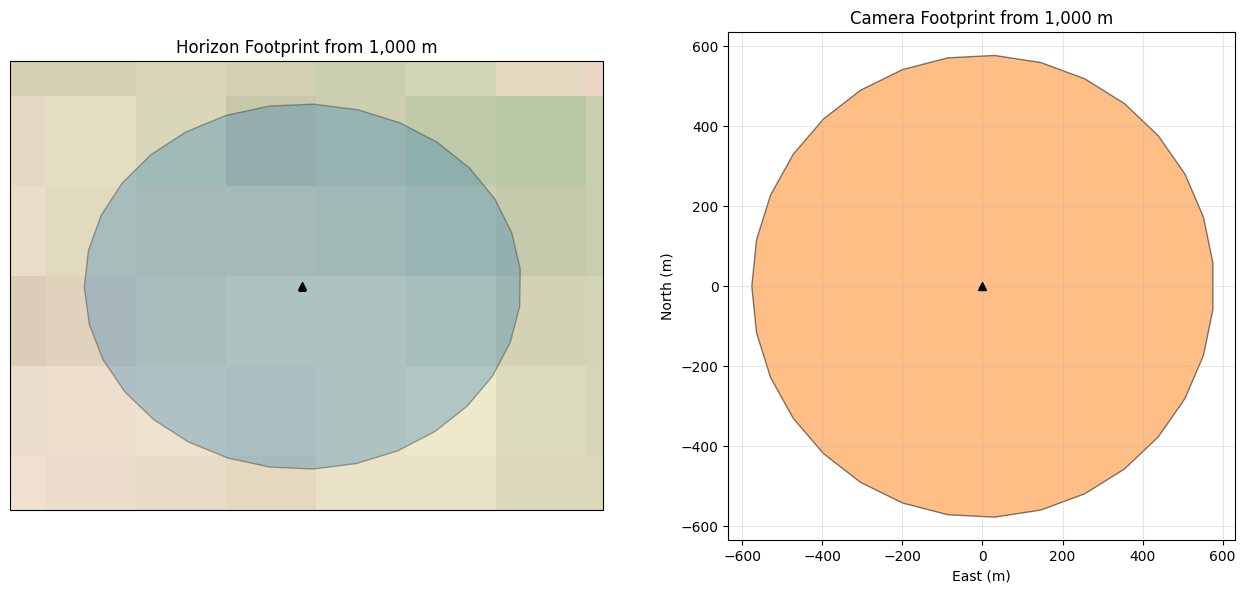

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(13, 6))
ax = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
results[results.instrument == "Horizon"].plot(
    facecolor="tab:blue", edgecolor="k", alpha=0.3, ax=ax, transform=ccrs.PlateCarree()
)
ax.plot(balloon.longitude, balloon.latitude, "k^", transform=ccrs.PlateCarree())
ax.stock_img()
ax.add_feature(cfeature.STATES, edgecolor="gray")
ax.set_extent([-113.7, -110.4, 32.2, 34.7], crs=ccrs.PlateCarree())
ax.set_title("Horizon Footprint from 1,000 m")

ax = fig.add_subplot(1, 2, 2)
results[results.instrument == "Camera"].to_crs(local_crs(balloon)).plot(
    facecolor="tab:orange", edgecolor="k", alpha=0.5, ax=ax
)
ax.plot(0, 0, "k^")
ax.set(xlabel="East (m)", ylabel="North (m)", title="Camera Footprint from 1,000 m", aspect="equal")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Platform Height

A platform's height governs how much it can see. The radius of a narrow view's footprint grows in proportion to height, while the distance to the horizon grows only with its square root. Collecting the balloon's footprints at several heights shows both trends: the camera footprint's radius doubles from 1,000 m to 2,000 m, while the horizon moves out by only about 40%.

In [5]:
heights = [100, 250, 500, 1000, 2000]
balloons = [balloon.model_copy(update={"name": f"{height} m", "height": height}) for height in heights]
by_height = collect_platform_track(balloons, instrument_index=None)
by_height["radius (km)"] = mean_radius(by_height, balloon) / 1e3
display(
    by_height.pivot(index="platform", columns="instrument", values="radius (km)")
    .loc[[balloon.name for balloon in balloons]]
    .round(3)
)

instrument,Camera,Horizon
platform,,
100 m,0.058,35.694
250 m,0.144,56.434
500 m,0.289,79.809
1000 m,0.577,112.863
2000 m,1.155,159.602


## Tower with Pointed Instruments

A `PointedInstrument` rotates its view away from nadir by a roll angle (positive to the left) and then a pitch angle (positive forward). On a satellite, left and forward are relative to its direction of motion; on a platform, they are relative to its `heading`, the azimuth (clockwise from north) of its forward direction.

The next platform is a 30 m tower in Tempe, Arizona, where the ground is about 350 m above mean sea level (320 m above the ellipsoid). Its heading is north (the default), and it hosts three pointed instruments:

 * `North camera`: a rectangular frame camera with a 60 degree horizontal and 40 degree vertical field of view. A 60 degree forward pitch points it north, 30 degrees below horizontal, so it views from 40 to 80 degrees from nadir. Pitching about the cross-track axis keeps the horizontal field of view across track.
 * `West camera`: the same camera rolled 60 degrees to the left (west). Rolling about the along-track axis turns the cross-track field of view vertical, so its fields of view are swapped (40 degrees across track and 60 degrees along track).
 * `Scanner`: a cross-track scanner (`ViewGeometry.SCAN`) sweeping 60 degrees to either side of nadir (east and west), with a 2 degree along-track field of view, as for a scanning radiometer.

In [6]:
from tatc.schemas import PointedInstrument
from tatc.utils import ViewGeometry

tower = SurfacePlatform(
    name="Tower",
    latitude=33.4242,
    longitude=-111.9281,
    elevation=320,
    height=30,
    instruments=[
        PointedInstrument(
            name="North camera",
            cross_track_field_of_view=60,
            along_track_field_of_view=40,
            pitch_angle=60,
            is_rectangular=True,
        ),
        PointedInstrument(
            name="West camera",
            cross_track_field_of_view=40,
            along_track_field_of_view=60,
            roll_angle=60,
            is_rectangular=True,
        ),
        PointedInstrument(
            name="Scanner",
            cross_track_field_of_view=120,
            along_track_field_of_view=2,
            view_geometry=ViewGeometry.SCAN,
            is_rectangular=True,
        ),
    ],
)

tower_results = collect_platform_track(tower, instrument_index=None)
display(tower_results)

,platform,instrument,elevation,geometry
0,Tower,North camera,320.0,"POLYGON Z ((-111.92833 33.42443 320, -111.9283..."
1,Tower,West camera,320.0,"POLYGON Z ((-111.92993 33.42335 320, -111.9299..."
2,Tower,Scanner,320.0,"POLYGON Z ((-111.92866 33.42419 320, -111.9286..."


In local coordinates, each camera's footprint is a trapezoid that widens with distance. Its near edge is 30 tan(40°) = 25 m from the tower, and its far edge 30 tan(80°) = 170 m. The scanner's footprint is a strip 30 tan(60°) = 52 m to either side of the tower, widening away from nadir because its along-track field of view is a constant angle.

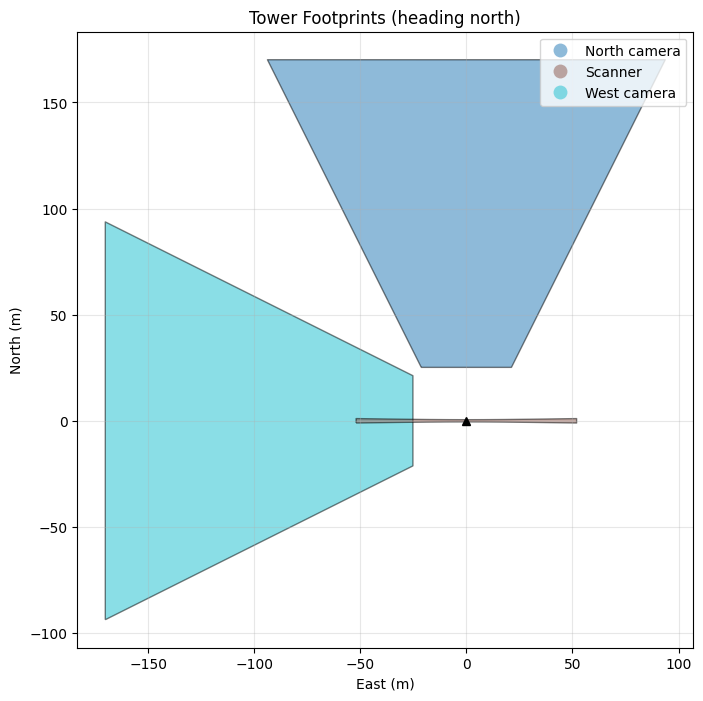

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
tower_results.to_crs(local_crs(tower)).plot(
    column="instrument", cmap="tab10", edgecolor="k", alpha=0.5, legend=True, ax=ax
)
ax.plot(0, 0, "k^")
ax.set(xlabel="East (m)", ylabel="North (m)", title="Tower Footprints (heading north)", aspect="equal")
ax.grid(True, alpha=0.3)
plt.show()

### Pixels

A `PointedInstrument` with `cross_track_pixels` and `along_track_pixels` defines a pixel array, and its `compute_footprint_pixel_array` method projects the pixel centers from the platform's track (`SurfacePlatform.get_track`). Seen at a slant from a tower, ground pixels stretch with distance. Here the north camera has 12 by 8 pixels. Along its central columns, rows are about 5 m apart near the tower and about 40 m apart at the far edge, and rows bow away from the tower at their ends, where off-axis pixels look farther from nadir.

row distances (m): [ 27.5  32.7  39.1  47.1  57.6  72.4  95.2 135.4]
row spacing (m): [ 5.3  6.4  8.  10.5 14.8 22.8 40.3]


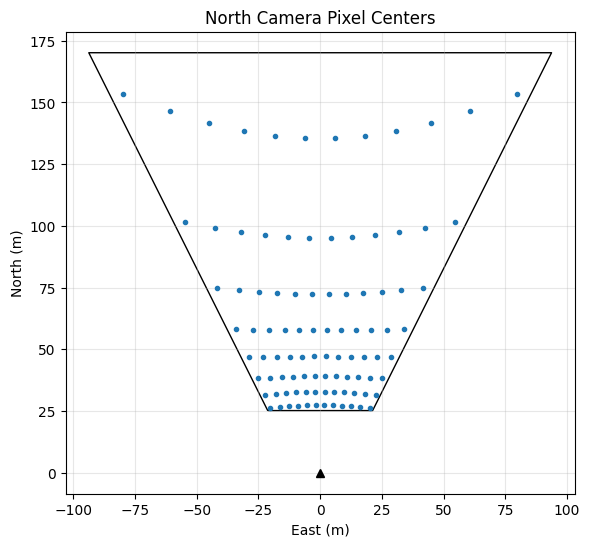

In [8]:
import geopandas as gpd

pixel_camera = tower.instruments[0].model_copy(update={"cross_track_pixels": 12, "along_track_pixels": 8})
pixels = pixel_camera.compute_footprint_pixel_array(tower.get_track(), elevation=tower.elevation)[0]
pixels_local = gpd.GeoSeries([pixels], crs="EPSG:4326").to_crs(local_crs(tower)).iloc[0]

# pixel centers by cross-track (right to left) and along-track (fore to aft) index
centers = np.array([(p.x, p.y) for p in pixels_local.geoms]).reshape(12, 8, 2)
# distances (north) of the rows, averaged over the two central columns
rows = np.sort(centers[5:7, :, 1].mean(axis=0))
print("row distances (m):", np.round(rows, 1))
print("row spacing (m):", np.round(np.diff(rows), 1))

fig, ax = plt.subplots(figsize=(8, 6))
tower_results[tower_results.instrument == "North camera"].to_crs(local_crs(tower)).plot(
    facecolor="none", edgecolor="k", ax=ax
)
ax.plot([p.x for p in pixels_local.geoms], [p.y for p in pixels_local.geoms], ".", color="tab:blue")
ax.plot(0, 0, "k^")
ax.set(xlabel="East (m)", ylabel="North (m)", title="North Camera Pixel Centers", aspect="equal")
ax.grid(True, alpha=0.3)
plt.show()

## Observation Conditions

Although footprints are static, an instrument's observation conditions can still vary with time, just as for a satellite. `SurfacePlatform.get_track` accepts times, and instrument methods such as `is_valid_observation` evaluate its requirements at each one. For example, the north camera may require the sun at least 10 degrees above the horizon at the center of its footprint (`min_target_solar_elevation`). Evaluated every 10 minutes on 16 October 2026, it observes from about 7:30 to 16:50 local time (Arizona does not observe daylight saving time, so local time is UTC-7).

first valid: 2026-10-16 07:30:00-07:00
last valid: 2026-10-16 16:50:00-07:00
valid fraction of the day: 39.6%


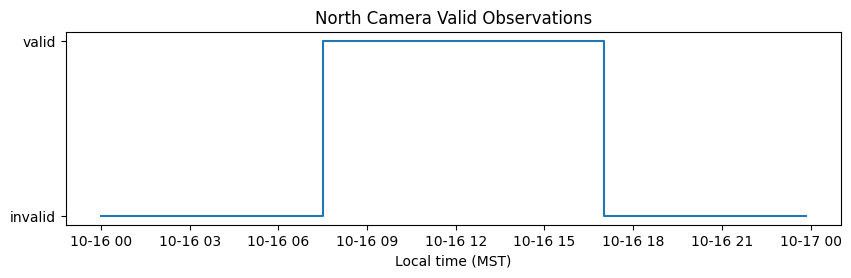

In [9]:
from datetime import datetime, timedelta, timezone

import pandas as pd

times = [datetime(2026, 10, 16, 7, tzinfo=timezone.utc) + timedelta(minutes=10 * i) for i in range(144)]
camera = tower.instruments[0].model_copy(update={"min_target_solar_elevation": 10})
track = tower.get_track(times)
center = camera.compute_footprint_center(track, elevation=tower.elevation)
valid = pd.Series(
    camera.is_valid_observation(track, center),
    index=pd.DatetimeIndex(times).tz_convert("America/Phoenix"),
)
print("first valid:", valid[valid].index[0])
print("last valid:", valid[valid].index[-1])
print(f"valid fraction of the day: {valid.mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.step(valid.index.tz_localize(None), valid.astype(int), where="post")
ax.set(yticks=[0, 1], yticklabels=["invalid", "valid"], xlabel="Local time (MST)", title="North Camera Valid Observations")
plt.show()

## Network Coverage

The `compute_platform_track` method dissolves the footprints of several platforms into a single composite geometry (for example, a network coverage map), optionally clipped to a mask. Here, a network of five tethered balloons flies 1,000 m above cities across the Phoenix metropolitan area. Each carries a downward-looking instrument with a 170 degree field of regard, which reaches to 5 degrees below the horizon, a radius of about 1,000 tan(85°) ≈ 11.4 km. Ground elevations are approximate. The mask clips the composite to the area south of 33.55°N.

composite area: 1575 km2
masked composite area: 1323 km2


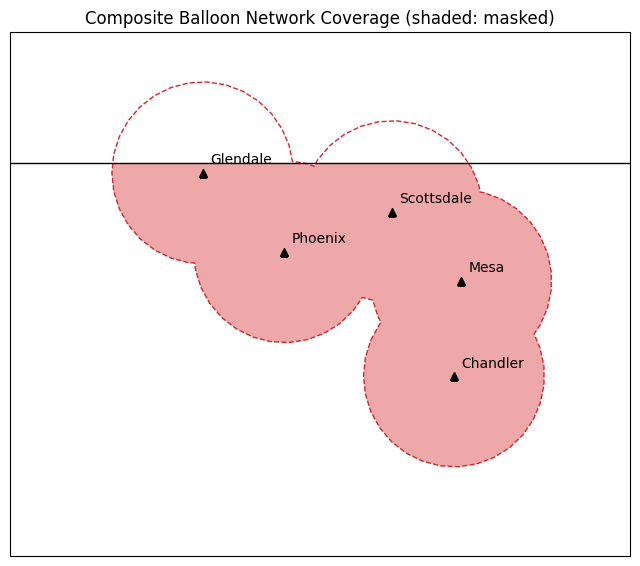

In [10]:
from shapely.geometry import box

from tatc.analysis import compute_platform_track

sites = {
    "Phoenix": (33.4484, -112.0740, 300),
    "Glendale": (33.5387, -112.1860, 320),
    "Scottsdale": (33.4942, -111.9261, 350),
    "Mesa": (33.4152, -111.8315, 350),
    "Chandler": (33.3062, -111.8413, 340),
}
network = [
    SurfacePlatform(
        name=name,
        latitude=latitude,
        longitude=longitude,
        elevation=elevation,
        height=1000,
        instruments=[Instrument(name="Imager", field_of_regard=170)],
    )
    for name, (latitude, longitude, elevation) in sites.items()
]
mask = box(-112.5, 33.0, -111.5, 33.55)

composite = compute_platform_track(network)
composite_masked = compute_platform_track(network, mask=mask)
print(f"composite area: {composite.to_crs(local_crs(network[0])).area.iloc[0] / 1e6:.0f} km2")
print(f"masked composite area: {composite_masked.to_crs(local_crs(network[0])).area.iloc[0] / 1e6:.0f} km2")

fig, ax = plt.subplots(figsize=(8, 7), subplot_kw={"projection": ccrs.PlateCarree()})
composite.plot(facecolor="none", edgecolor="tab:red", ls="--", ax=ax, transform=ccrs.PlateCarree())
composite_masked.plot(facecolor="tab:red", edgecolor="none", alpha=0.4, ax=ax, transform=ccrs.PlateCarree())
ax.plot(*mask.exterior.xy, color="k", lw=1, transform=ccrs.PlateCarree())
for platform in network:
    ax.plot(platform.longitude, platform.latitude, "k^", transform=ccrs.PlateCarree())
    ax.text(platform.longitude + 0.01, platform.latitude + 0.01, platform.name, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, edgecolor="gray")
ax.set_extent([-112.45, -111.6, 33.1, 33.7], crs=ccrs.PlateCarree())
ax.set_title("Composite Balloon Network Coverage (shaded: masked)")
plt.show()

## Limitations

Footprints are projected onto a target elevation below the instruments, the same geometry as a satellite looking down at the Earth. Views that look up from a platform at a higher target elevation (for example, from a tower to a cloud layer) are not supported: `collect_platform_track` raises a `ValueError` for a target elevation at or above a platform's instruments. Footprints do not account for terrain, obstructions, or atmospheric refraction, and `ConicalInstrument` views, which depend on a satellite's motion, are not supported on platforms.